BMI 500 — Homework 3, Part B

Bias Analysis Using Synthetic Blood Pressure Data

In this notebook, I generate synthetic blood pressure data, train classifiers, and test ways to reduce bias. All results and figures are shown directly in the notebook, so no external CSV is needed.

I use the parameters given in the homework, with male = 1 and female = 0. Each dataset has 60,000 samples, with a 70/30 train-test split and a separate balanced test set of 10,000 samples. Fixed random seeds make the experiments reproducible.

In [15]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from IPython.display import display, Markdown
from scipy.stats import chi2
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix)

SEED = 20261013
FIGURES = Path('figures')
OUTPUTS = Path('outputs')
FIGURES.mkdir(parents=True, exist_ok=True)
OUTPUTS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 115, 'savefig.dpi': 175, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
print(f'Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__}')

def show_plot(filename):
    plt.tight_layout()
    plt.savefig(FIGURES / filename, bbox_inches='tight')
    plt.show()

Python 3.13.5 | numpy 2.1.3 | pandas 2.2.3


## B(i). Generate Synthetic Blood Pressure Data

I used bivariate normal distributions to generate SBP and DBP data for males and females, following the parameters given in the homework. The test data were generated separately from the training data.

In [29]:
PARAMS = {
    1: {'sex': 'Male', 'mu_sbp':133.0, 'sd_sbp':18.6,
        'mu_dbp':78.8, 'sd_dbp':12.6, 'rho':0.45},
    0: {'sex': 'Female', 'mu_sbp':125.8, 'sd_sbp':19.0,
        'mu_dbp':74.8, 'sd_dbp':12.4, 'rho':0.50},
}

def theoretical_mean_cov(label):
    p = PARAMS[label]
    mean = np.array([p['mu_sbp'], p['mu_dbp']], dtype=float)
    cross = p['rho'] * p['sd_sbp'] * p['sd_dbp']
    cov = np.array([[p['sd_sbp']**2, cross],
                    [cross, p['sd_dbp']**2]])
    return mean, cov

def draw_sex(label, n, rng):
    mu, cov = theoretical_mean_cov(label)
    return rng.multivariate_normal(mu, cov, size=int(n))

def make_dataset(n, fraction_male, seed):
    rng = np.random.default_rng(seed)
    n_male = round(n*fraction_male)
    n_female = n-n_male
    X = np.vstack([draw_sex(1, n_male, rng), draw_sex(0, n_female, rng)])
    y = np.r_[np.ones(n_male, dtype=int), np.zeros(n_female, dtype=int)]
    perm = rng.permutation(n)
    return X[perm], y[perm]

specification = pd.DataFrame(PARAMS).T.set_index('sex')
specification.index.name = 'label'
display(specification)
for sex in (0,1):
    _, cov = theoretical_mean_cov(sex)
    assert np.all(np.linalg.eigvalsh(cov)>0), 'Covariance must be positive definite'

,mu_sbp,sd_sbp,mu_dbp,sd_dbp,rho
label,,,,,
Male,133.0,18.6,78.8,12.6,0.45
Female,125.8,19.0,74.8,12.4,0.5


In [105]:
ratios = [('50/50',0.50), ('75/25',0.75), ('90/10',0.90), ('97/3',0.97)]
ratio_names = [name for name,_ in ratios]

datasets = {}
for i, (name, fraction_male) in enumerate(ratios):
    X, y = make_dataset(n=60_000, fraction_male=fraction_male,
                        seed=SEED+100+i)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.30, stratify=y, random_state=101
    )
    datasets[name] = dict(X_train=X_train, X_test=X_test,
                          y_train=y_train, y_test=y_test)
X_bal, y_bal = make_dataset(n=10_000, fraction_male=0.50, seed=SEED+900)

rows=[]
for name,p in datasets.items():
    rows.append({'Male/female ratio':name,
                 'Train total': len(p['y_train']),
                 'Train male':int(p['y_train'].sum()),
                 'Train female':int((p['y_train']==0).sum()),
                 'Own test total':len(p['y_test'])})
display(pd.DataFrame(rows))
print('Independent balanced test:', len(y_bal), 'samples;',
      'male:', int(y_bal.sum()), 'female:',int((y_bal==0).sum()))

,Male/female ratio,Train total,Train male,Train female,Own test total
0,50/50,42000,21000,21000,18000
1,75/25,42000,31500,10500,18000
2,90/10,42000,37800,4200,18000
3,97/3,42000,40740,1260,18000


Independent balanced test: 10000 samples; male: 5000 female: 5000


### Distributions and 95% Probability Ellipses

I plotted the male and female blood pressure distributions with 95% probability ellipses to show their overlap and explain why classification is difficult.

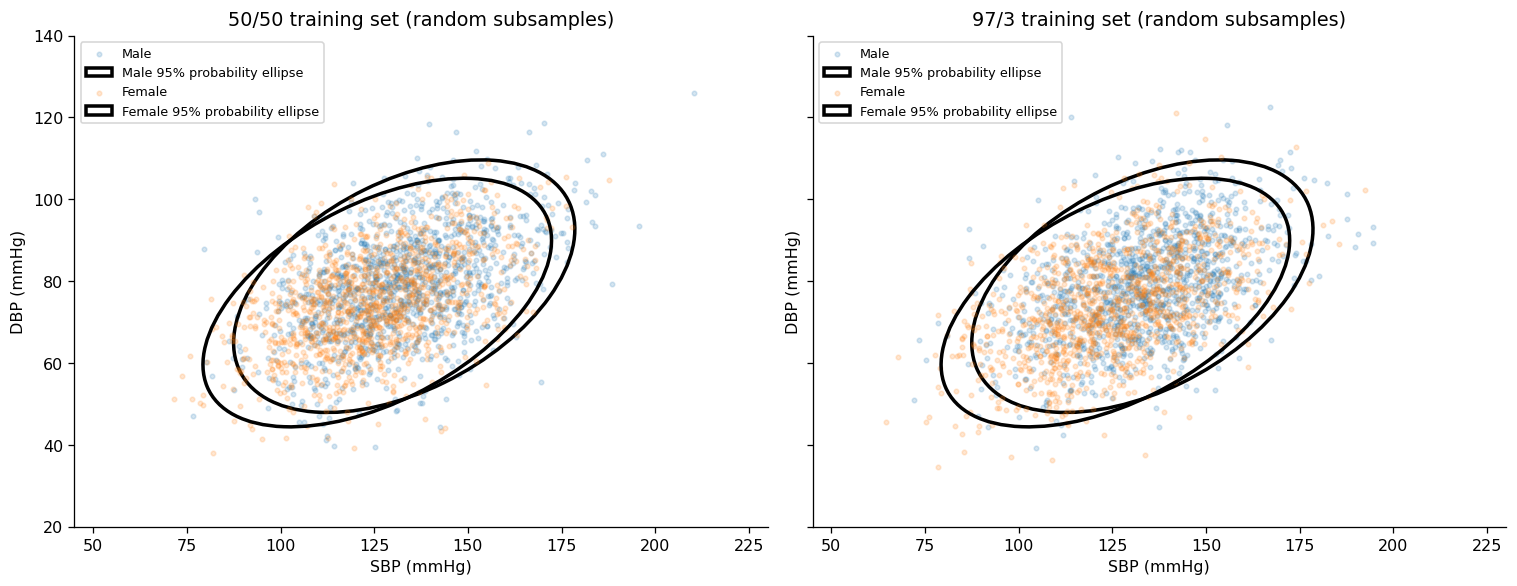

In [117]:
def add_probability_ellipse(ax, label):
    mean,cov=theoretical_mean_cov(label)
    eigenvalues,eigenvectors=np.linalg.eigh(cov)
    order=eigenvalues.argsort()[::-1]
    eigenvalues=eigenvalues[order]
    eigenvectors=eigenvectors[:,order]
    angle=np.degrees(np.arctan2(eigenvectors[1,0],eigenvectors[0,0]))
    radius=np.sqrt(chi2.ppf(0.95,df=2))
    ellipse=Ellipse(xy=mean, width=2*radius*np.sqrt(eigenvalues[0]),
                    height=2*radius*np.sqrt(eigenvalues[1]),
                    angle=angle,fill=False,linewidth=2.2,
                    label=f"{PARAMS[label]['sex']} 95% probability ellipse")
    ax.add_patch(ellipse)

fig,axes=plt.subplots(1,2,figsize=(13.3,5.2),sharex=True,sharey=True)
for ax,(name, data) in zip(axes,[('50/50',datasets['50/50']),
                                    ('97/3',datasets['97/3'])]):
    for label in (1,0):
        pts=data['X_train'][data['y_train']==label]
        idx=np.random.default_rng(SEED+label).choice(len(pts),
                     min(1200,len(pts)),replace=False)
        ax.scatter(pts[idx,0],pts[idx,1],s=8,alpha=0.18,
                   label=PARAMS[label]['sex'])
        add_probability_ellipse(ax,label)
    ax.set(title=f'{name} training set (random subsamples)',xlabel='SBP (mmHg)',
           ylabel='DBP (mmHg)',xlim=(45,230),ylim=(20,140))
    ax.legend(fontsize=8,loc='upper left')
show_plot('partB_01_joint_distributions.png')

## B(ii). Binary Classification

I trained four Logistic Regression models using SBP and DBP, then tested them on both imbalanced and balanced datasets. I compared accuracy, F1, AUC, and recall for males and females.

In [128]:
def fit_classifier(X_train,y_train, female_weight=None):
    weights=None if female_weight is None else {0:float(female_weight),1:1.0}
    model=make_pipeline(StandardScaler(),
                        LogisticRegression(max_iter=500,solver='lbfgs',
                                           class_weight=weights))
    model.fit(X_train,y_train)
    return model

def evaluate_proba(y_true, p_male, set_name, model_name, threshold=0.5):
    pred=(p_male>=threshold).astype(int)
    cm=confusion_matrix(y_true,pred,labels=[0,1])
    recall_female=cm[0,0]/cm[0].sum()
    recall_male=cm[1,1]/cm[1].sum()
    return {'Model':model_name,'Test set':set_name,
            'Accuracy':accuracy_score(y_true,pred),
            'F1 (male+)':f1_score(y_true,pred,pos_label=1,zero_division=0),
            'Macro-F1':f1_score(y_true,pred,average='macro',zero_division=0),
            'ROC AUC':roc_auc_score(y_true,p_male),
            'Male recall':recall_male,'Female recall':recall_female,
            'Recall gap |M-F|':abs(recall_male-recall_female)}

base_models={}
metrics=[]
for name,data in datasets.items():
    model=fit_classifier(data['X_train'],data['y_train'])
    base_models[name]=model
    for test_name,X,y in [('Own 30% test',data['X_test'],data['y_test']),
                          ('Balanced 10k test',X_bal,y_bal)]:
        p=model.predict_proba(X)[:,1]
        metrics.append(evaluate_proba(y,p,test_name,name))

metrics_df=pd.DataFrame(metrics)
metrics_df.to_csv(OUTPUTS/'partB_classification_metrics.csv',index=False)
cols=['Model','Test set','Accuracy','F1 (male+)','Macro-F1','ROC AUC',
      'Male recall','Female recall','Recall gap |M-F|']
display(metrics_df[cols].round(4))

,Model,Test set,Accuracy,F1 (male+),Macro-F1,ROC AUC,Male recall,Female recall,Recall gap |M-F|
0,50/50,Own 30% test,0.5817,0.5841,0.5817,0.6132,0.5874,0.5760,0.0114
1,50/50,Balanced 10k test,0.5852,0.5889,0.5852,0.6162,0.5942,0.5762,0.0180
2,75/25,Own 30% test,0.7511,0.8573,0.4417,0.6164,0.9970,0.0133,0.9836
3,75/25,Balanced 10k test,0.5031,0.6675,0.3424,0.6159,0.9974,0.0088,0.9886
4,90/10,Own 30% test,0.9000,0.9474,0.4737,0.6114,1.0000,0.0000,1.0000
5,90/10,Balanced 10k test,0.5000,0.6667,0.3333,0.6161,1.0000,0.0000,1.0000
6,97/3,Own 30% test,0.9700,0.9848,0.4924,0.6002,1.0000,0.0000,1.0000
7,97/3,Balanced 10k test,0.5000,0.6667,0.3333,0.6161,1.0000,0.0000,1.0000


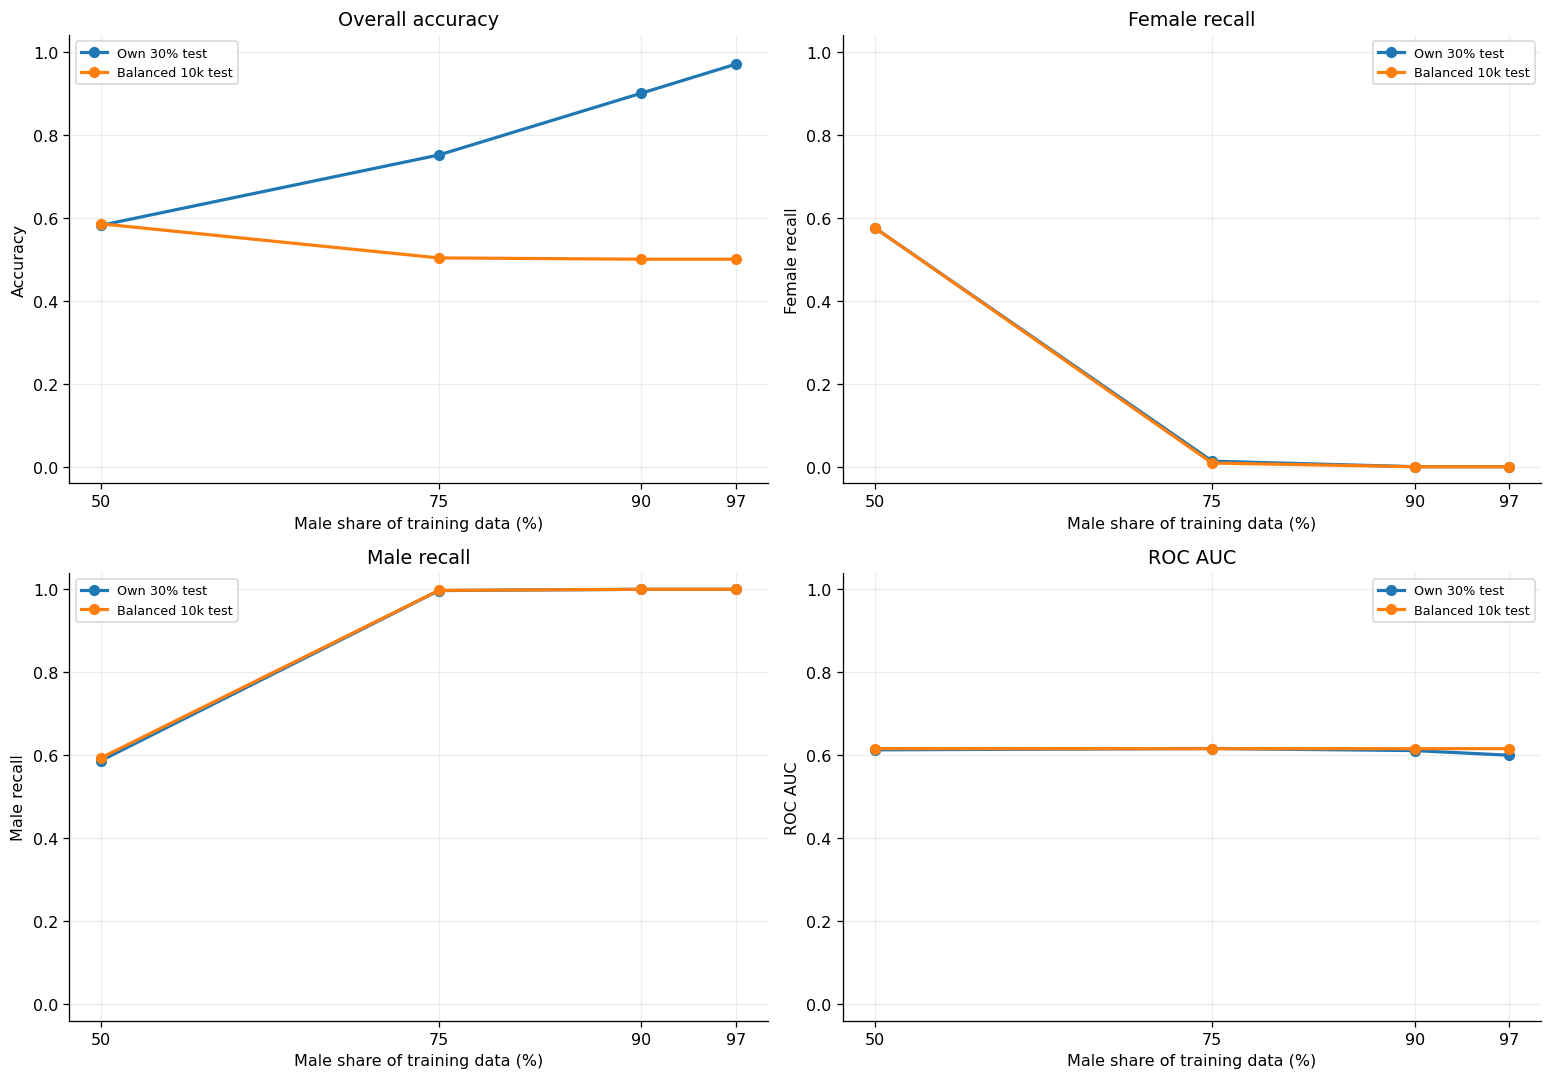

In [129]:
fig,axes=plt.subplots(2,2,figsize=(13.6,9.5))
metric_panels=[('Accuracy','Overall accuracy'),('Female recall','Female recall'),
               ('Male recall','Male recall'),('ROC AUC','ROC AUC')]
for ax,(metric,title) in zip(axes.flat,metric_panels):
    for set_name in ['Own 30% test','Balanced 10k test']:
        frame=metrics_df[metrics_df['Test set']==set_name].set_index('Model')
        ax.plot([50,75,90,97],frame.loc[ratio_names,metric].to_numpy(),
                marker='o',linewidth=2,label=set_name)
    ax.set(title=title,xlabel='Male share of training data (%)',
           ylabel=metric,ylim=(-0.04,1.04),xticks=[50,75,90,97])
    ax.grid(alpha=0.22)
    ax.legend(fontsize=8)
show_plot('partB_02_imbalance_metric_curves.png')

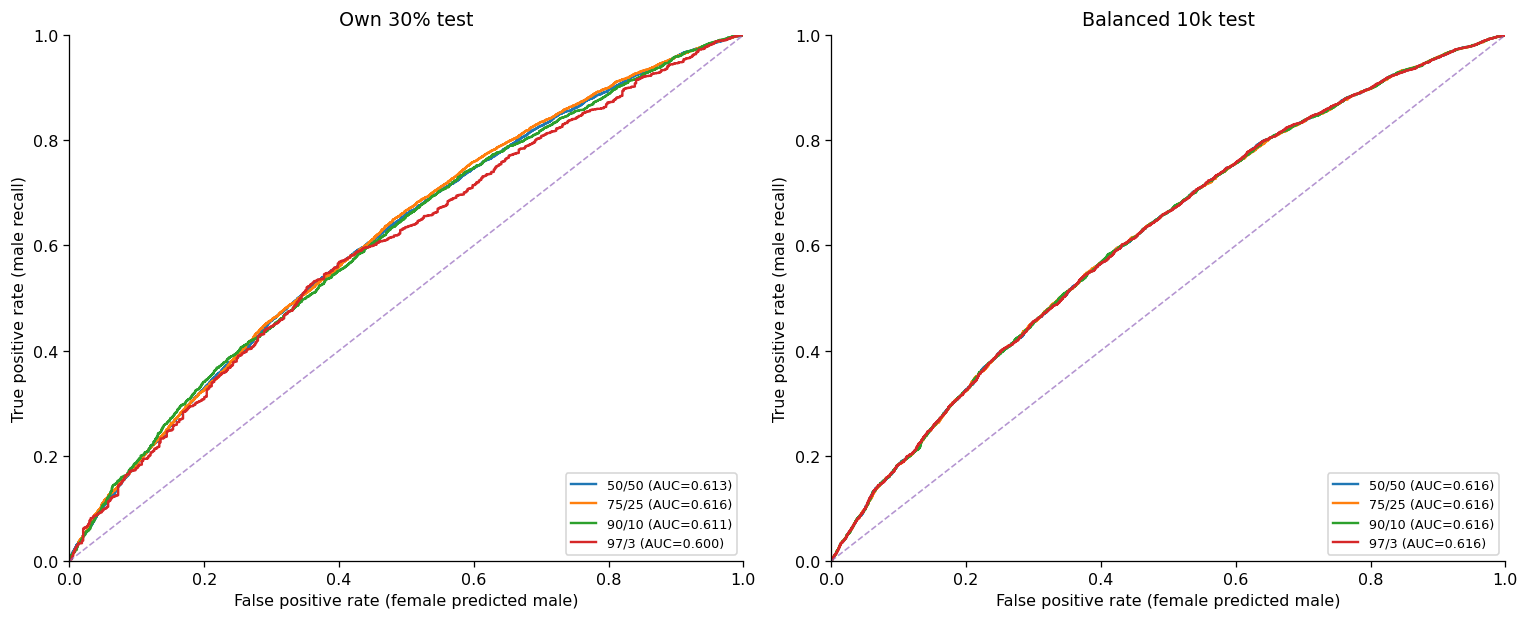

In [130]:
fig,axes=plt.subplots(1,2,figsize=(13.4,5.5))
for ax,test_name in zip(axes,['Own 30% test','Balanced 10k test']):
    for name,dat in datasets.items():
        if test_name=='Own 30% test':
            X,y=dat['X_test'],dat['y_test']
        else:
            X,y=X_bal,y_bal
        scores=base_models[name].predict_proba(X)[:,1]
        fpr,tpr,_=roc_curve(y,scores)
        auc=roc_auc_score(y,scores)
        ax.plot(fpr,tpr,label=f'{name} (AUC={auc:.3f})')
    ax.plot([0,1],[0,1],linestyle='--',linewidth=1,alpha=0.7)
    ax.set(title=test_name,xlabel='False positive rate (female predicted male)',
           ylabel='True positive rate (male recall)',xlim=(0,1),ylim=(0,1))
    ax.legend(loc='lower right',fontsize=8)
show_plot('partB_03_roc_own_vs_balanced.png')

### B(ii–iii). Discussion

As the male ratio increases, accuracy becomes misleading because the model predicts almost everyone as male, leaving female recall near zero.

AUC stays relatively stable because it measures how well the model ranks predictions rather than using a fixed threshold.

This shows why healthcare models should be evaluated for both accuracy and fairness, especially for underrepresented groups.

In [131]:
wide=metrics_df.pivot(index='Model',columns='Test set',
                      values=['Accuracy','Female recall','Male recall','ROC AUC'])
summary=pd.DataFrame({
    'Male share':ratio_names,
    'Own accuracy':[metrics_df.query('Model==@r and `Test set`=="Own 30% test"')['Accuracy'].iloc[0] for r in ratio_names],
    'Balanced accuracy':[metrics_df.query('Model==@r and `Test set`=="Balanced 10k test"')['Accuracy'].iloc[0] for r in ratio_names],
    'Balanced female recall':[metrics_df.query('Model==@r and `Test set`=="Balanced 10k test"')['Female recall'].iloc[0] for r in ratio_names],
    'Balanced male recall':[metrics_df.query('Model==@r and `Test set`=="Balanced 10k test"')['Male recall'].iloc[0] for r in ratio_names],
})
display(summary.round(3))

,Male share,Own accuracy,Balanced accuracy,Balanced female recall,Balanced male recall
0,50/50,0.582,0.585,0.576,0.594
1,75/25,0.751,0.503,0.009,0.997
2,90/10,0.900,0.500,0.000,1.000
3,97/3,0.970,0.500,0.000,1.000


## B(iv). Bias mitigation using the 90/10 training set

The lecture calls for the penalized objective \(C(\theta)=f(\theta)+\lambda\phi(\theta)\), with \(\phi\) the **absolute difference between male and female recalls**. Since hard recall is non-differentiable, the homework explicitly permits **grid search over class weights and the threshold**.

Here **\(f\) is the usual 0–1 misclassification loss on a population-balanced validation distribution**, calculated as \(1-(R_M+R_F)/2\) from the separate validation split; this equals a 50/50-weighted error. The fairness term is \(\phi=|R_M-R_F|\). **A balanced test set is *not* used to choose weights or thresholds.** Class-weighted logistic regression is optimized with logistic loss on the fitting split; weight/threshold configurations are selected using the stated penalized validation objective.

We subdivide **only** the 90/10 training set into 80% fitting / 20% validation, preserving the original 30% hold-out test. For each \(\lambda\), the lowest-scoring candidate is evaluated once on the untouched balanced test. Since the grid is finite, this is an approximate solution of the penalized empirical objective.

In [138]:
training_9010=datasets['90/10']
X_fit,X_val,y_fit,y_val=train_test_split(
    training_9010['X_train'],training_9010['y_train'],
    test_size=0.20,stratify=training_9010['y_train'],random_state=SEED+700)

female_weights=[1,2,3,5,7,10,15,20]
thresholds=np.linspace(0.20,0.85,66)
lambdas=[0.0,0.01,0.03,0.05,0.10,0.20,0.35,0.50,0.75,1.0]

candidate_models={}
candidate_rows=[]
for w in female_weights:
    model=fit_classifier(X_fit,y_fit,female_weight=w)
    candidate_models[w]=model
    probabilities=model.predict_proba(X_val)[:,1]
    for th in thresholds:
        pred=(probabilities>=th).astype(int)
        rec_m=(pred[y_val==1]==1).mean()
        rec_f=(pred[y_val==0]==0).mean()
        bal_accuracy=0.5*(rec_m+rec_f)
        candidate_rows.append({'female_weight':w,'threshold':float(th),
                              'validation balanced error':1-bal_accuracy,
                              'validation recall gap':abs(rec_m-rec_f),
                              'validation balanced accuracy':bal_accuracy,
                              'validation male recall':rec_m,
                              'validation female recall':rec_f})
candidates=pd.DataFrame(candidate_rows)

selected=[]
for lam in lambdas:
    cost=(candidates['validation balanced error']+
          lam*candidates['validation recall gap'])
    idx=cost.sort_values(kind='stable').index[0]
    best=candidates.loc[idx]
    w=int(best['female_weight'])
    threshold=float(best['threshold'])
    p_test=candidate_models[w].predict_proba(X_bal)[:,1]
    score=evaluate_proba(y_bal,p_test,'Balanced 10k test',f'lambda={lam:g}',threshold)
    selected.append({'lambda':lam,'female_weight':w,
                     'threshold':threshold,'validation objective':cost.loc[idx],
                     'validation balanced accuracy':best['validation balanced accuracy'],
                     'validation recall gap':best['validation recall gap'],
                     **score})
fair_df=pd.DataFrame(selected)
base_bal=metrics_df[(metrics_df['Model']=='90/10') &
                    (metrics_df['Test set']=='Balanced 10k test')].iloc[0]
fair_df.to_csv(OUTPUTS/'partB_fairness_tradeoff.csv',index=False)
display(fair_df[['lambda','female_weight','threshold',
                 'validation balanced accuracy','validation recall gap',
                 'Accuracy','Male recall','Female recall','Recall gap |M-F|']].round(4))
print(f"Unmodified 90/10 baseline (balanced test): accuracy={base_bal['Accuracy']:.3f}, "
      f"recall gap={base_bal['Recall gap |M-F|']:.3f}")

,lambda,female_weight,threshold,validation balanced accuracy,validation recall gap,Accuracy,Male recall,Female recall,Recall gap |M-F|
0,0.00,15,0.38,0.5858,0.0332,0.5837,0.5688,0.5986,0.0298
1,0.01,15,0.38,0.5858,0.0332,0.5837,0.5688,0.5986,0.0298
2,0.03,15,0.38,0.5858,0.0332,0.5837,0.5688,0.5986,0.0298
3,0.05,15,0.38,0.5858,0.0332,0.5837,0.5688,0.5986,0.0298
4,0.10,2,0.82,0.5840,0.0082,0.5852,0.5802,0.5902,0.0100
5,0.20,2,0.82,0.5840,0.0082,0.5852,0.5802,0.5902,0.0100
6,0.35,2,0.82,0.5840,0.0082,0.5852,0.5802,0.5902,0.0100
7,0.50,2,0.82,0.5840,0.0082,0.5852,0.5802,0.5902,0.0100
8,0.75,2,0.82,0.5840,0.0082,0.5852,0.5802,0.5902,0.0100
9,1.00,2,0.82,0.5840,0.0082,0.5852,0.5802,0.5902,0.0100


Unmodified 90/10 baseline (balanced test): accuracy=0.500, recall gap=1.000


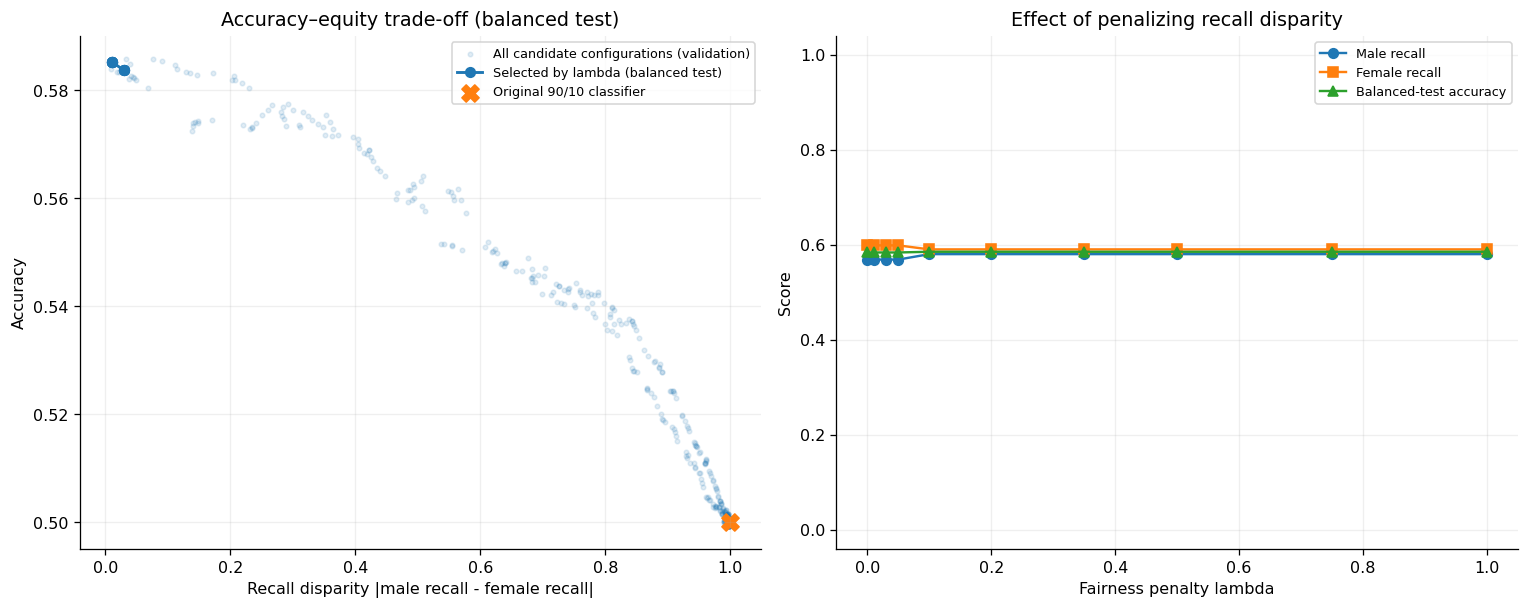

In [139]:
fig,axes=plt.subplots(1,2,figsize=(13.4,5.4))
ax=axes[0]
ax.scatter(candidates['validation recall gap'],
           candidates['validation balanced accuracy'],s=8,alpha=0.13,
           label='All candidate configurations (validation)')
ax.plot(fair_df['Recall gap |M-F|'],fair_df['Accuracy'],'o-',
        markersize=6,linewidth=1.8,label='Selected by lambda (balanced test)')
ax.scatter([base_bal['Recall gap |M-F|']],[base_bal['Accuracy']],
           marker='X',s=115,label='Original 90/10 classifier')
ax.set(xlabel='Recall disparity |male recall - female recall|',
       ylabel='Accuracy',title='Accuracy–equity trade-off (balanced test)')
ax.grid(alpha=0.2);ax.legend(fontsize=8)

ax=axes[1]
ax.plot(fair_df['lambda'],fair_df['Male recall'],'o-',label='Male recall')
ax.plot(fair_df['lambda'],fair_df['Female recall'],'s-',label='Female recall')
ax.plot(fair_df['lambda'],fair_df['Accuracy'],'^-',label='Balanced-test accuracy')
ax.set(xlabel='Fairness penalty lambda',ylabel='Score',ylim=(-0.04,1.04),
       title='Effect of penalizing recall disparity')
ax.grid(alpha=0.2);ax.legend(fontsize=8)
show_plot('partB_04_fairness_penalty.png')

Increasing the fairness penalty can reduce the gap between male and female recall, but it may affect accuracy, and equal recall on synthetic data does not guarantee real-world fairness.

## B(v). Synthetic Female Augmentation

I added synthetic female samples to the original 90/10 training set until the data became balanced, keeping the male samples unchanged. I compared two methods: Gaussian sampling from the true female distribution and uniform sampling over a wide blood pressure range.

All models were tested on the same independent balanced test set to see which method worked better. Uniform sampling may produce unrealistic female data.

In [148]:
X90 = training_9010['X_train']
y90 = training_9010['y_train']
original_male = int(np.sum(y90 == 1))
original_female = int(np.sum(y90 == 0))
n_extra = original_male - original_female
assert n_extra > 0
rng_gauss = np.random.default_rng(SEED + 1200)
rng_uniform = np.random.default_rng(SEED + 1300)
extra_gaussian = draw_sex(0, n_extra, rng_gauss)
extra_uniform = np.column_stack([
    rng_uniform.uniform(70, 210, n_extra),
    rng_uniform.uniform(35, 125, n_extra)
])
def augment_females(extra):
    X_aug = np.vstack([X90, extra])
    y_aug = np.r_[y90, np.zeros(len(extra), dtype=int)]
    assert np.sum(y_aug == 0) == np.sum(y_aug == 1)
    return X_aug, y_aug

X_gauss, y_gauss = augment_females(extra_gaussian)
X_unif, y_unif = augment_females(extra_uniform)
augmentation_models = {
    'Original 90/10': base_models['90/10'],
    'Gaussian augmentation': fit_classifier(X_gauss, y_gauss),
    'Uniform augmentation': fit_classifier(X_unif, y_unif),
}

# Evaluate only on the independent balanced test set
augmentation_scores = []

for method, model in augmentation_models.items():
    augmentation_scores.append(
        evaluate_proba(
            y_bal,
            model.predict_proba(X_bal)[:, 1],
            'Balanced 10k test',
            method
        )
    )

augment_df = pd.DataFrame(augmentation_scores)
augment_df.to_csv(
    OUTPUTS / 'partB_augmentation_metrics.csv',
    index=False
)
display(pd.DataFrame([
    {
        'Method': 'Original 90/10',
        'Training males': original_male,
        'Training females': original_female,
        'New female samples': 0
    },
    {
        'Method': 'Gaussian augmentation',
        'Training males': original_male,
        'Training females': original_female + n_extra,
        'New female samples': n_extra
    },
    {
        'Method': 'Uniform augmentation',
        'Training males': original_male,
        'Training females': original_female + n_extra,
        'New female samples': n_extra
    }
]))
display(
    augment_df[
        [
            'Model',
            'Accuracy',
            'F1 (male+)',
            'ROC AUC',
            'Male recall',
            'Female recall',
            'Recall gap |M-F|'
        ]
    ].round(4)
)


,Method,Training males,Training females,New female samples
0,Original 90/10,37800,4200,0
1,Gaussian augmentation,37800,37800,33600
2,Uniform augmentation,37800,37800,33600


,Model,Accuracy,F1 (male+),ROC AUC,Male recall,Female recall,Recall gap |M-F|
0,Original 90/10,0.5000,0.6667,0.6161,1.0000,0.000,1.0000
1,Gaussian augmentation,0.5846,0.5885,0.6160,0.5942,0.575,0.0192
2,Uniform augmentation,0.4252,0.4873,0.3938,0.5464,0.304,0.2424


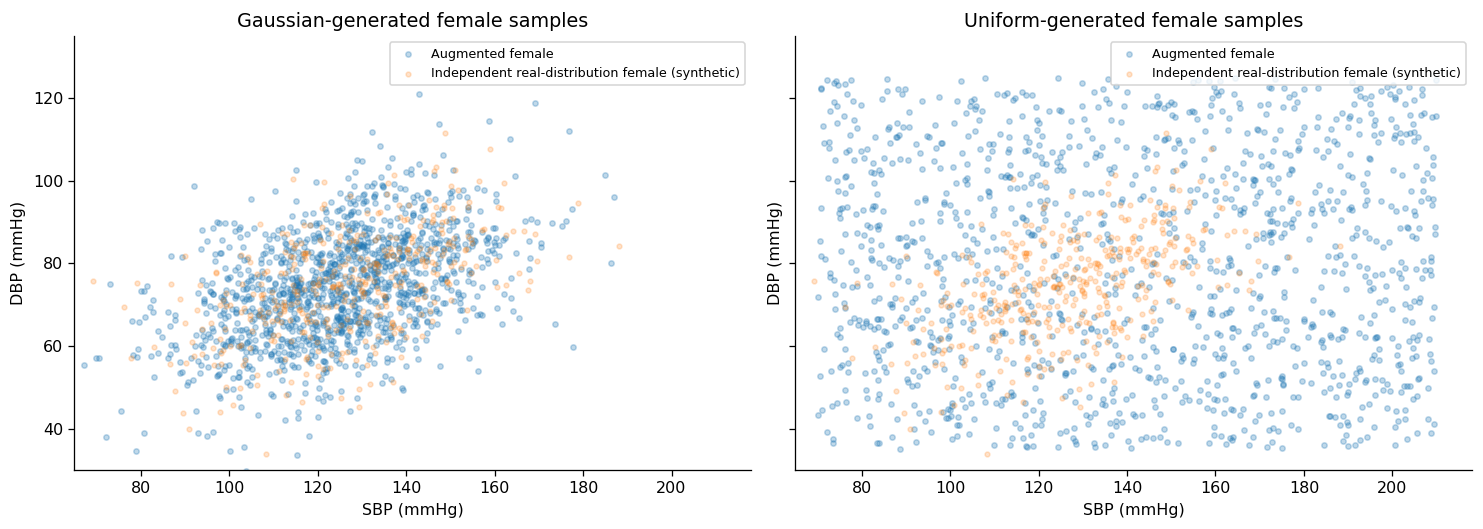

In [152]:
fig,axes=plt.subplots(1,2,figsize=(13,4.7),sharex=True,sharey=True)
for ax,extra,title in zip(axes,[extra_gaussian,extra_uniform],
                          ['Gaussian-generated female samples',
                           'Uniform-generated female samples']):
    rng=np.random.default_rng(SEED+1700)
    idx=rng.choice(len(extra),size=min(1300,len(extra)),replace=False)
    ax.scatter(extra[idx,0],extra[idx,1],s=11,alpha=0.28,label='Augmented female')
    ax.scatter(X_bal[y_bal==0,0][:400],X_bal[y_bal==0,1][:400],
               s=9,alpha=0.21,label='Independent real-distribution female (synthetic)')
    ax.set(title=title,xlabel='SBP (mmHg)',ylabel='DBP (mmHg)',
           xlim=(65,218),ylim=(30,135))
    ax.legend(fontsize=8)
show_plot('partB_05_gaussian_vs_uniform_samples.png')

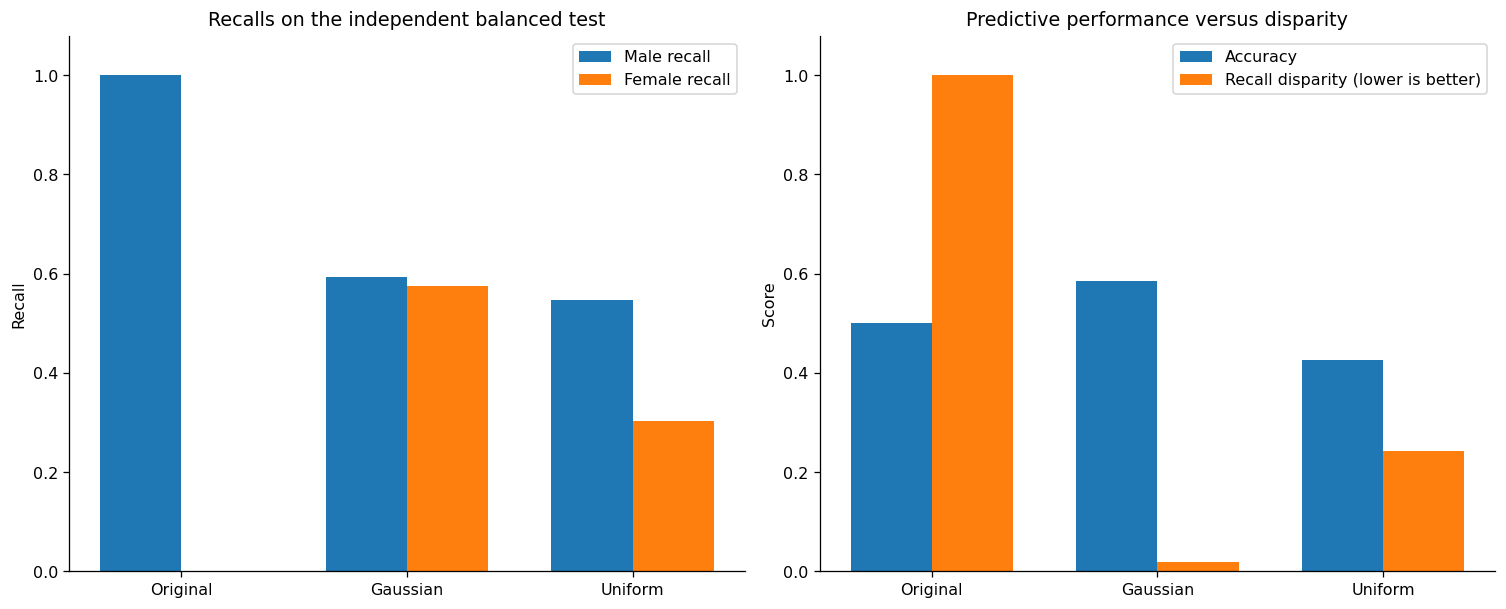

In [153]:
aug_bal=augment_df[augment_df['Test set']=='Balanced 10k test'].set_index('Model')
methods=['Original 90/10','Gaussian augmentation','Uniform augmentation']
fig,axes=plt.subplots(1,2,figsize=(13.2,5.4))
x=np.arange(len(methods))
bar_width=0.36
axes[0].bar(x-bar_width/2,aug_bal.loc[methods,'Male recall'],bar_width,label='Male recall')
axes[0].bar(x+bar_width/2,aug_bal.loc[methods,'Female recall'],bar_width,label='Female recall')
axes[0].set(title='Recalls on the independent balanced test',ylabel='Recall',
            xticks=x,xticklabels=['Original','Gaussian','Uniform'],ylim=(0,1.08))
axes[0].legend()
axes[1].bar(x-bar_width/2,aug_bal.loc[methods,'Accuracy'],bar_width,label='Accuracy')
axes[1].bar(x+bar_width/2,aug_bal.loc[methods,'Recall gap |M-F|'],bar_width,
            label='Recall disparity (lower is better)')
axes[1].set(title='Predictive performance versus disparity',ylabel='Score',
            xticks=x,xticklabels=['Original','Gaussian','Uniform'],ylim=(0,1.08))
axes[1].legend()
show_plot('partB_06_augmentation_performance.png')